# 04 · Gröbner Degeneration

**Arithmetic Without Addition Lab**  |  Initial ideals, S-polynomials and a flat family

---

## A trap in the phrase “keep the leading term”

Consider the ideal $I=(x+y,x-y)$ over $\mathbb Q$. With lex order $x>y$, the *displayed generators* have leading term $x$; naive replacement would suggest the monomial ideal $(x)$. But subtracting the two generators produces $2y$, so the actual ideal is $(x,y)$. Its initial ideal is $(x,y)$, not $(x)$.

A Gröbner basis makes a finite generating set sufficient for controlling the **entire** ideal's leading terms. This subtlety parallels the tropical-basis issue in Experiment 03.

In [1]:
import sympy as sp
import matplotlib.pyplot as plt
from awa_lab.groebner import groebner_leading_monomials, standard_monomials, verify_flat_example
x,y,t=sp.symbols('x y t')
F=[x+y,x-y]
print('Leading monomials from displayed generators: [(1,0),(1,0)]')
print('True Groebner leading monomials:',groebner_leading_monomials(F,(x,y)))
assert groebner_leading_monomials(F,(x,y))==[(1,0),(0,1)]
for bound in range(5):
    naive=standard_monomials([(1,0)],2,bound)
    true=standard_monomials([(1,0),(0,1)],2,bound)
    print('Degree <=',bound,'naive quotient dimension',len(naive),'true quotient dimension',len(true))

Leading monomials from displayed generators: [(1,0),(1,0)]
True Groebner leading monomials: [(1, 0), (0, 1)]
Degree <= 0 naive quotient dimension 1 true quotient dimension 1
Degree <= 1 naive quotient dimension 2 true quotient dimension 1
Degree <= 2 naive quotient dimension 3 true quotient dimension 1
Degree <= 3 naive quotient dimension 4 true quotient dimension 1
Degree <= 4 naive quotient dimension 5 true quotient dimension 1


## Flat degeneration is stronger than just taking a limit

The family $xy=t$ has generic fibers ($t\ne0$) isomorphic to a one-dimensional torus, but its special fiber ($t=0$) is the union of the two coordinate axes. It is **flat** over the $t$-line.

A direct argument: the total-space coordinate ring
$$\mathbb Q[t,x,y]/(xy-t)\cong\mathbb Q[x,y]$$
contains $\mathbb Q[t]$ through $t\mapsto xy$. As a $\mathbb Q[t]$-module it is torsion-free (multiplication by a nonzero polynomial in $xy$ is injective in the domain $\mathbb Q[x,y]$), and modules over the PID $\mathbb Q[t]$ are flat. The geometric fiber becomes reducible without arbitrary loss of algebraic information.

Contrast this with merely substituting $t=0$ in an arbitrary family: the word **flat** is what excludes many pathological jumps.

Generic fiber t=1: x*y - 1
Special fiber t=0: x*y


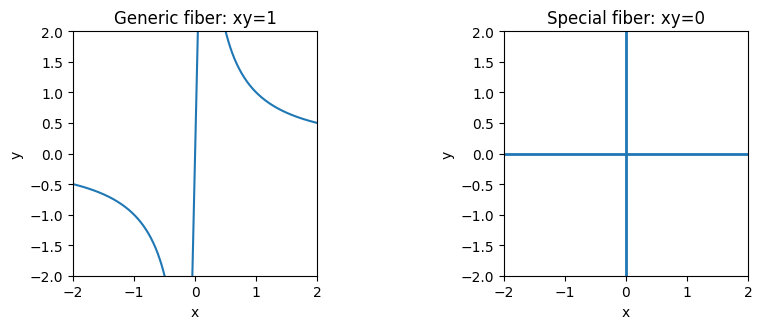

In [2]:
F=x*y-t
print('Generic fiber t=1:',sp.factor(F.subs(t,1)))
print('Special fiber t=0:',sp.factor(F.subs(t,0)))
import numpy as np
xx=np.concatenate((np.linspace(-2,-0.15,250),np.linspace(0.15,2,250)))
fig,axes=plt.subplots(1,2,figsize=(9,3.4))
axes[0].plot(xx,1/xx);axes[0].set(xlim=(-2,2),ylim=(-2,2),title='Generic fiber: xy=1')
axes[1].axhline(0,linewidth=2);axes[1].axvline(0,linewidth=2);axes[1].set(xlim=(-2,2),ylim=(-2,2),title='Special fiber: xy=0')
for ax in axes: ax.set_aspect('equal'); ax.set(xlabel='x',ylabel='y')
plt.tight_layout();plt.show()

## Why Hilbert functions matter

For a homogeneous ideal $I$, the quotient $k[x_1,\ldots,x_n]/I$ and its initial monomial quotient have the same Hilbert function. One can often count standard monomials much faster than solving polynomial equations. The defining mechanism behind Gröbner degeneration is a *controlled* passage from algebraic geometry to combinatorics.

For inhomogeneous examples like $(x+y,x-y)$ above, the degree-**filtered** quotient illustrates the same issue. Do not conflate its cumulative dimensions with the homogeneous graded Hilbert function.

### Investigate

1. Compute a Gröbner basis of $I=(x^2-y,y^2-x)$ in lex order $x>y$. Draw the standard monomials of the quotient up to degree six.
2. Find an ideal whose displayed generators do not form a Gröbner basis. Use an S-polynomial to explain why.
3. Why does a nodal special fiber of $xy=t$ not contradict flatness? Which invariants actually remain fixed in a proper flat family?
4. Explain why tropical initial ideals and Gröbner initial ideals are related but are not identical concepts.